---
title: "L3-10 · Estimation, intervals, and repeated tests"
short_title: "Estimation, intervals, and repeated tests"
subtitle: "An estimate is one draw from a sampling distribution whose spread shrinks like $1/\\sqrt{n}$; a 95% interval is a recipe that captures the truth in about 95% of repetitions, and running many tests guarantees some false alarms unless the threshold is adjusted."
description: "Estimate a probability from repeated trials with its standard error, construct and correctly interpret a 95% confidence interval as a statement about a procedure, and quantify how repeated testing inflates false positives."
tags: [level-3, coursebook]
---

(lesson-l3-10)=

:::{div}
:class: qcai-meta
![Level 3 icon](../../_static/icons/qicon-level-3.svg) **Level 3 · High-school bridge** · about 95 minutes  
**Big idea.** An estimate is one draw from a sampling distribution whose spread shrinks like $1/\sqrt{n}$; a 95% interval is a recipe that captures the truth in about 95% of repetitions, and running many tests guarantees some false alarms unless the threshold is adjusted.  
**Before this lesson.** [L3-07](#lesson-l3-07)  
**Lab.** [Chance and repeated trials](../../labs/01-chance.ipynb)
:::

## What you will be able to do

- Compute $\hat p = k/n$, its standard error $\sqrt{\hat p(1-\hat p)/n}$ and a 95% Wald interval, and prove that $\mathbb{E}[\hat p] = p$ and $\operatorname{Var}(\hat p) = p(1-p)/n$.
- Explain the coverage meaning of a confidence interval, and identify incorrect interpretations of a single computed interval.
- Use Chebyshev's inequality and the $1/\sqrt{n}$ law to choose a number of trials for a desired precision.
- Compute the chance of at least one false positive among $m$ tests and apply the Bonferroni correction, stating its assumptions.

## Why this matters

A quantum computer is run 1000 times and outcome 0 appears 532 times. A drug trial reports a 95% confidence interval. A study tests 20 foods for a link to an illness and finds one "significant" result. Each number came from random data, so each would come out differently if the experiment were repeated. Without a way to describe that variation, we cannot say whether 0.532 is close to the truth, what the interval promises, or whether the food result is a discovery or an accident.

This lesson turns the expectation and variance of [L3-07](#lesson-l3-07) into tools for inference. The central object is the sampling distribution: the distribution of an estimate over imagined repetitions. It explains why precision grows only like $\sqrt{n}$, what the 95% in a confidence interval really refers to, and why a researcher who runs enough tests will always find something that looks significant [@openstax_ci].

:::{dropdown} Key terms

**Estimator**
: A rule that turns data into a guess for an unknown quantity, such as $\hat p = K/n$ for a probability $p$. Its value changes from sample to sample.

**Sampling distribution**
: The distribution of an estimator over repeated samples of the same size from the same process.

**Standard error**
: The standard deviation of the sampling distribution; for $\hat p$ it is $\sqrt{p(1-p)/n}$, estimated by $\sqrt{\hat p(1-\hat p)/n}$.

**Confidence interval**
: An interval computed from data by a recipe that, over repeated samples, contains the true value with a stated probability (the coverage).

**p-value**
: The probability, computed assuming the null hypothesis, of a result at least as extreme as the one observed.

**Family-wise error rate**
: The probability of at least one false positive among a family of tests.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l3_10 as _lessonfigs

## Estimating a probability from trials

Repeat a yes/no trial $n$ times independently, each with the same unknown success probability $p$. Let $X_i = 1$ for a success and $0$ otherwise, and let $K = X_1 + \dots + X_n$ count the successes. The natural estimate is the observed fraction.

:::{prf:definition} Sample proportion and standard error
:label: def-l3-10-phat
The **sample proportion** is $\hat p = K/n$. Its **standard error** is its standard deviation over repeated samples, $\operatorname{SE}(\hat p) = \sqrt{p(1-p)/n}$; since $p$ is unknown we report the estimate $\sqrt{\hat p(1-\hat p)/n}$.
:::

:::{prf:proposition} Mean and variance of the sample proportion
:label: prop-l3-10-meanvar
$\mathbb{E}[\hat p] = p$ (the estimator is unbiased) and $\operatorname{Var}(\hat p) = p(1-p)/n$.
:::

:::{prf:proof}
Each $X_i$ is 0 or 1 with $P(X_i = 1) = p$, so $\mathbb{E}[X_i] = p$ and, because $X_i^2 = X_i$, $\operatorname{Var}(X_i) = \mathbb{E}[X_i^2] - p^2 = p - p^2 = p(1-p)$. Linearity of expectation gives $\mathbb{E}[K] = np$, hence $\mathbb{E}[\hat p] = p$. For independent variables variances add ([L3-07](#lesson-l3-07)), so $\operatorname{Var}(K) = np(1-p)$, and scaling by $1/n$ multiplies the variance by $1/n^2$: $\operatorname{Var}(\hat p) = p(1-p)/n$.
:::

$$
\operatorname{SE}(\hat p) = \sqrt{\frac{p(1-p)}{n}} \le \frac{1}{2\sqrt{n}}
$$ (eq-l3-10-se)

:::{prf:example} 56 successes in 100 trials
:label: ex-l3-10-56
With $k = 56$ and $n = 100$: $\hat p = 0.56$ and the estimated standard error is $\sqrt{0.56 \times 0.44/100} = \sqrt{0.002464} \approx 0.0496$. The bound in [](#eq-l3-10-se), $1/(2\sqrt{n}) = 0.05$, holds for every $p$ because $p(1-p) \le \tfrac14$.
:::

## The sampling distribution narrows like 1/sqrt(n)

:::{figure} ../../_static/animations/l3_10_sampling_narrows.mp4
:alt: Three histograms of the sample proportion for 25, 100 and 400 trials, each taller and half as wide as the one before, with an amber bar marking 1.96 standard errors either side of 0.5.
:width: 100%

The exact distribution of $\hat p$ when $p = 0.5$, for $n = 25, 100, 400$. Each fourfold increase in $n$ halves the standard error: $0.1$, $0.05$, $0.025$.
:::

:::{dropdown} What the animation shows
A histogram shows the exact binomial probabilities of each value of $\hat p$ for $n = 25$ trials with $p = 0.5$, drawn as a density so that the total area is 1. An amber bar spans 1.96 standard errors either side of 0.5. The formula $\text{SE} = \sqrt{p(1-p)/n}$ is shown, with the row $n = 25$: SE $= 0.1$. The histogram then morphs into the one for $n = 100$ (SE $= 0.05$), twice as tall and half as wide, and then into $n = 400$ (SE $= 0.025$). The final line reads $n \times 4 \Rightarrow \text{SE} \div 2$.
:::

:::{prf:lemma} Chebyshev's inequality
:label: lem-l3-10-chebyshev
For any random variable $Y$ with mean $\mu$ and variance $\sigma^2$, and any $\varepsilon > 0$: $P(|Y - \mu| \ge \varepsilon) \le \sigma^2/\varepsilon^2$. It was proved in [L3-07](#lesson-l3-07) by splitting a sum; here is a shorter proof with an indicator variable.
:::

:::{prf:proof}
Let $A$ be the event $|Y - \mu| \ge \varepsilon$ and $\mathbf{1}_A$ its indicator. On $A$ we have $(Y - \mu)^2 \ge \varepsilon^2 = \varepsilon^2 \mathbf{1}_A$, and off $A$ we have $(Y - \mu)^2 \ge 0 = \varepsilon^2\mathbf{1}_A$. So $(Y - \mu)^2 \ge \varepsilon^2 \mathbf{1}_A$ always. Taking expectations, $\sigma^2 \ge \varepsilon^2 P(A)$.
:::

:::{prf:theorem} Precision of the sample proportion
:label: thm-l3-10-precision
For every $p$ and every $\varepsilon > 0$, $\; P(|\hat p - p| \ge \varepsilon) \le \dfrac{p(1-p)}{n\varepsilon^2} \le \dfrac{1}{4n\varepsilon^2}$. In particular $\hat p \to p$ in probability as $n \to \infty$ (the weak law of large numbers).
:::

:::{prf:proof}
Apply [](#lem-l3-10-chebyshev) to $Y = \hat p$, using $\mathbb{E}[\hat p] = p$ and $\operatorname{Var}(\hat p) = p(1-p)/n$ from [](#prop-l3-10-meanvar), and then $p(1-p) \le \tfrac14$. The right side tends to 0 as $n$ grows, for any fixed $\varepsilon$.
:::

:::{prf:remark} Sharper statements, stated without proof
Chebyshev is safe but loose. The **central limit theorem** (in this case the de Moivre-Laplace theorem) says that $(\hat p - p)/\operatorname{SE}(\hat p)$ is approximately standard normal for large $n$, so $|\hat p - p| \le 1.96\,\operatorname{SE}$ with probability close to 0.95 [@openstax]. **Hoeffding's inequality** gives a guaranteed bound for every $n$: $P(|\hat p - p| \ge \varepsilon) \le 2e^{-2n\varepsilon^2}$ [@hoeffding1963]. For a margin $\varepsilon = 0.05$ with 95% confidence the three approaches ask for $385$ (normal approximation), $738$ (Hoeffding) and $2000$ (Chebyshev) trials.
:::

:::{tip} Shots on a quantum computer
Estimating the probability of outcome 0 from $n$ measurement shots is exactly this problem. With $n = 1000$ shots the standard error is at most $1/(2\sqrt{1000}) \approx 0.0158$, so 532 zeros gives $\hat p = 0.532$ with a 95% margin of about $0.031$. Halving that margin costs four times as many shots.
:::

## Confidence intervals: what 95% means

:::{prf:definition} Confidence interval and coverage
:label: def-l3-10-ci
A **95% confidence interval procedure** is a rule that maps each possible data set to an interval $[L, U]$ such that, for the true parameter value $p$, $P(L \le p \le U) \approx 0.95$, where the probability is over repeated samples. This probability is the **coverage** of the procedure. Once the data are in, the computed interval is fixed, and it either contains $p$ or it does not.
:::

$$
\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/n}
$$ (eq-l3-10-wald)

Formula [](#eq-l3-10-wald) is the **Wald interval**. It comes from the normal approximation: about 95% of the time $\hat p$ lands within $1.96$ standard errors of $p$, and when it does, $p$ lies within $1.96$ standard errors of $\hat p$. For 56 successes in 100 trials it gives $0.56 \pm 0.0973$, that is $[0.463, 0.657]$.

:::{figure} ../../_static/animations/l3_10_intervals_coverage.mp4
:alt: Forty horizontal interval bars stacked around a dashed vertical line at the true probability 0.3; two red bars miss the line.
:width: 100%

Forty studies of $n = 100$ trials each, true $p = 0.3$. Each computes $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/n}$. In this run 2 of the 40 intervals miss; the exact coverage of the recipe here is 0.950.
:::

:::{dropdown} What the animation shows
A number line from 0.1 to 0.5 has a dashed vertical line at the true value $p = 0.3$. The recipe is shown: each study has $n = 100$ trials and reports $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/n}$. One after another, 40 horizontal bars appear, stacked upward, each centered on its own estimate. Bars that contain 0.3 are blue; a bar that misses turns red and a counter goes up. In this run the counter ends at 2 missed of 40, and the two red bars are boxed: one lies entirely below 0.3 and one entirely above. A note gives the exact coverage of the procedure at $n = 100$, $p = 0.3$: 0.950. It ends with the statement that each bar either contains $p$ or not, and 95% describes the recipe over many repetitions.
:::


In [2]:
_show(_lessonfigs.coverage_explorer())

**Explore.** Change the number of trials per study. Left: 40 simulated studies with true $p = 0.3$ and their 95% Wald intervals. Right: the exact coverage of the Wald recipe for every true $p$; it dips well below 95% when $n$ is small or $p$ is near 0 or 1.

:::{dropdown} What the figure shows
Left panel: 40 horizontal intervals around a dashed line at 0.3, blue if they cover it and red if they miss; as $n$ grows the intervals shrink. Right panel: exact coverage against the true $p$, jagged because $K$ is a whole number, with a dashed line at 0.95. At $n = 100$ the curve stays near 0.93 to 0.95 for most $p$ and drops sharply near the ends; at $n = 10$ it is under 0.9 for most $p$ and comes close to 0.95 only in two narrow ranges near 0.43 and 0.57.
:::

:::{important} What a computed interval does not say
For the interval $[0.463, 0.657]$ it is **not** correct, in this framework, to say "there is a 95% probability that $p$ is between 0.463 and 0.657": $p$ is a fixed number, and the interval is now fixed too. The 95% describes the recipe: if many independent studies each used it, about 95% of their intervals would contain $p$. A statement of probability about $p$ itself requires a Bayesian model with a prior, as in Level 2.
:::

:::{prf:remark} The Wald interval is approximate
The Wald recipe covers at exactly 95% only in the large-$n$ limit. Its exact coverage is 0.950 at $n = 100, p = 0.3$ but 0.943 at $p = 0.5$, 0.876 at $n = 20, p = 0.1$, and 0.840 at $n = 10, p = 0.3$; its coverage swings erratically with $n$ and $p$ [@browncai2001]. With $k = 0$ it collapses to the single point $[0, 0]$. The **Wilson (score) interval** [@wilson1927], $\dfrac{\hat p + \frac{z^2}{2n}}{1 + \frac{z^2}{n}} \pm \dfrac{z}{1 + \frac{z^2}{n}}\sqrt{\dfrac{\hat p(1-\hat p)}{n} + \dfrac{z^2}{4n^2}}$ with $z = 1.96$, has coverage much closer to 95% for small samples [@browncai2001]; for 56 of 100 it gives $[0.462, 0.653]$.
:::

## Tests, p-values, and repeated tests

:::{prf:definition} Null hypothesis and p-value
:label: def-l3-10-pvalue
A **null hypothesis** $H_0$ is a specific claim, such as $p = 0.5$. Choose a test statistic $T$ that tends to be large when the data disagree with $H_0$. The **p-value** of the observed value $t$ is $P_{H_0}(T \ge t)$, the probability of a result at least as extreme if $H_0$ were true. A test at level $\alpha$ rejects $H_0$ when the p-value is at most $\alpha$.
:::

:::{prf:example} Is the coin fair?
:label: ex-l3-10-test
Test $H_0: p = 0.5$ with $T = |K - 50|$ and the data $k = 56$ of $n = 100$, so $t = 6$. By the symmetry of the binomial distribution with $p = 0.5$, the p-value is $P(|K - 50| \ge 6) = 2P(K \ge 56) = 2 \times 0.1356 \approx 0.271$. The normal approximation, $z = (0.56 - 0.5)/0.05 = 1.2$, gives $\approx 0.230$. Either way the data are quite compatible with a fair coin. This matches the interval: $[0.463, 0.657]$ contains 0.5.
:::

:::{prf:proposition} Level of a test
:label: prop-l3-10-level
If $T$ has a continuous distribution under $H_0$, the p-value is uniformly distributed on $[0, 1]$ under $H_0$, so a level-$\alpha$ test makes a false rejection with probability exactly $\alpha$. (For discrete statistics like $K$, the probability is at most $\alpha$.)
:::

:::{prf:proof}
Let $G(t) = P_{H_0}(T \ge t)$, so the p-value is $G(T)$. For a continuous distribution $G$ is continuous and non-increasing, from 1 down to 0. Fix $0 < u < 1$ and let $t_u$ be the smallest $t$ with $G(t) \le u$; by continuity $G(t_u) = u$, and because $G$ is non-increasing, $G(t) \le u$ holds exactly for $t \ge t_u$. Hence $P_{H_0}(G(T) \le u) = P_{H_0}(T \ge t_u) = G(t_u) = u$, which is the uniform distribution.
:::

:::{prf:proposition} Repeated tests and the Bonferroni correction
:label: prop-l3-10-bonferroni
Run $m$ tests whose null hypotheses are all true, each at level $\alpha$. (a) If the tests are independent, $P(\text{at least one false positive}) = 1 - (1 - \alpha)^m$. (b) Without any independence assumption, testing each at level $\alpha/m$ (the Bonferroni correction [@dunn1961]) gives $P(\text{at least one false positive}) \le \alpha$.
:::

:::{prf:proof}
(a) Each test avoids a false positive with probability $1 - \alpha$; by independence all $m$ do with probability $(1 - \alpha)^m$, and the complement is at least one false positive. (b) Let $A_j$ be the event that test $j$ falsely rejects, so $P(A_j) \le \alpha/m$. The union bound $P(A_1 \cup \dots \cup A_m) \le \sum_j P(A_j)$ holds for any events, giving at most $m \cdot \alpha/m = \alpha$.
:::

:::{figure} ../../_static/animations/l3_10_multiple_testing.mp4
:alt: A grid of 20 p-values with two cells turning red below 0.05, a rising curve of 1 minus 0.95 to the power m, and the red cells clearing under the Bonferroni threshold.
:width: 100%

Twenty tests of true null hypotheses: two p-values fall below 0.05 by chance. The chance of at least one false positive, $1 - 0.95^{m}$, is 0.642 at $m = 20$. The Bonferroni threshold $0.05/20 = 0.0025$ clears both.
:::

:::{dropdown} What the animation shows
A grid of 20 cells shows simulated p-values from 20 tests in which every null hypothesis is true, so each p-value is uniform between 0 and 1. With the rule "flag if the p-value is below 0.05", two cells (0.045 and 0.049) turn red: 2 false positives. Next to the grid, axes plot $P(\text{at least one false positive}) = 1 - 0.95^{m}$ against the number of tests $m$; a red dot traces the curve up to $m = 20$, where a dashed marker reads 0.642, and on to $m = 60$, near 0.95. Finally the rule changes to Bonferroni, flag if $p < 0.05/20 = 0.0025$; the red cells clear, and the note says that the family error rate is at most 0.05.
:::


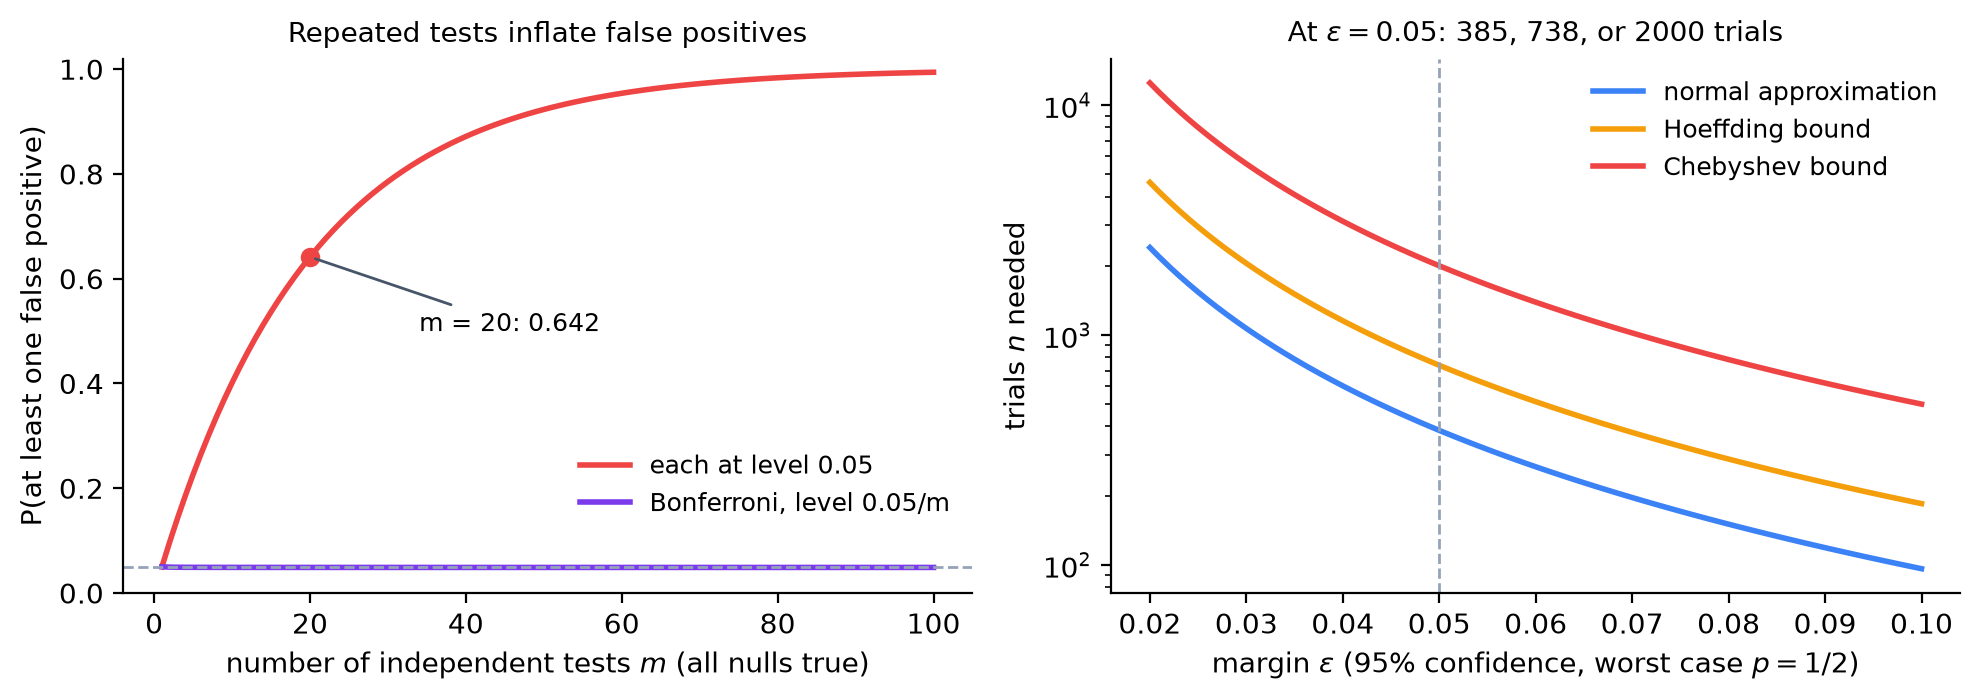

In [3]:
_show_mpl(_lessonfigs.repeated_tests())

*Left: with $m$ independent true-null tests at level 0.05, the chance of at least one false positive grows as $1 - 0.95^{m}$ (0.642 at $m = 20$); Bonferroni keeps it below 0.05. Right: trials needed for a margin $\varepsilon$ with 95% confidence by the normal approximation, Hoeffding's bound and Chebyshev's bound; at $\varepsilon = 0.05$ they give 385, 738 and 2000.*

:::{warning} Hidden repetition
Repeated testing is not always visible. Trying several outcomes, subgroups, time windows or analysis choices and reporting the one that "worked" is $m$ tests in disguise, and so is checking the data repeatedly and stopping as soon as $p < 0.05$. The guarantees above hold only if the number of tests and the stopping rule were fixed in advance and every test is reported.
:::

## Compute it

Estimate, standard error, the Wald and Wilson intervals, and the exact and approximate p-values for 56 successes in 100 trials.


In [4]:
import math

def binom_pmf(k, n, p):
    return math.comb(n, k) * p**k * (1 - p) ** (n - k)

k, n = 56, 100
p_hat = k / n
se = math.sqrt(p_hat * (1 - p_hat) / n)
print('estimate', p_hat, ' standard error', round(se, 4))
print('95% Wald interval  ', round(p_hat - 1.96 * se, 3), round(p_hat + 1.96 * se, 3))

z = 1.96   # Wilson (score) interval: better coverage for small n or p near 0 or 1
c = (p_hat + z**2 / (2 * n)) / (1 + z**2 / n)
h = z / (1 + z**2 / n) * math.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2))
print('95% Wilson interval', round(c - h, 3), round(c + h, 3))

# test of H0: p = 0.5.  Two-sided exact p-value: P(|K - 50| >= 6) = 2 P(K >= 56) by symmetry
print('exact binomial p-value', round(2 * sum(binom_pmf(j, n, 0.5) for j in range(56, n + 1)), 3))
z_obs = (p_hat - 0.5) / math.sqrt(0.25 / n)          # two-sided normal tail: P(|Z| >= z) = erfc(z / sqrt 2)
print('normal approximation  ', round(math.erfc(z_obs / math.sqrt(2)), 3))

estimate 0.56  standard error 0.0496
95% Wald interval   0.463 0.657
95% Wilson interval 0.462 0.653
exact binomial p-value 0.271
normal approximation   0.23


Coverage two ways: by simulating 20,000 repeated studies, and exactly by summing binomial probabilities over the outcomes $k$ whose interval contains $p$.


In [5]:
import numpy as np

def wald_covers(k, n, p):
    p_hat = k / n
    se = np.sqrt(p_hat * (1 - p_hat) / n)
    return (p_hat - 1.96 * se <= p) & (p <= p_hat + 1.96 * se)

def exact_coverage(n, p):
    k = np.arange(n + 1)
    pmf = np.array([binom_pmf(int(j), n, p) for j in k])
    return pmf[wald_covers(k, n, p)].sum()

rng = np.random.default_rng(10)
for n, p in [(100, 0.3), (100, 0.5), (20, 0.1), (10, 0.3)]:
    k = rng.binomial(n, p, size=20_000)          # 20,000 repeated studies
    print(f'n = {n:>3}, p = {p}: simulated coverage {wald_covers(k, n, p).mean():.3f}, exact {exact_coverage(n, p):.3f}')

n = 100, p = 0.3: simulated coverage 0.950, exact 0.950
n = 100, p = 0.5: simulated coverage 0.942, exact 0.943
n =  20, p = 0.1: simulated coverage 0.879, exact 0.876
n =  10, p = 0.3: simulated coverage 0.834, exact 0.840


Repeated tests by simulation, the Bonferroni correction, and the number of trials each bound asks for.


In [6]:
# 20 independent tests, every null hypothesis true: p-values are uniform on (0, 1)
rng = np.random.default_rng(20)
pvals = rng.uniform(size=(100_000, 20))          # 100,000 repeated families of 20 tests
print('P(at least one p < 0.05): simulated', (pvals < 0.05).any(axis=1).mean().round(3), ' exact', round(1 - 0.95**20, 3))
print('average number of false positives:', (pvals < 0.05).sum(axis=1).mean().round(3), ' exact', 20 * 0.05)
print('Bonferroni, p < 0.0025:  simulated', (pvals < 0.0025).any(axis=1).mean().round(4), ' exact', round(1 - 0.9975**20, 4))

# trials needed for a margin of 0.05 with 95% confidence (worst case p = 1/2)
eps, delta = 0.05, 0.05
print('normal approximation:', math.ceil((1.96 / (2 * eps)) ** 2))
print('Hoeffding bound:     ', math.ceil(math.log(2 / delta) / (2 * eps**2)))
print('Chebyshev bound:     ', math.ceil(1 / (4 * delta * eps**2)))

P(at least one p < 0.05): simulated 0.64  exact 0.642
average number of false positives: 0.996  exact 1.0
Bonferroni, p < 0.0025:  simulated 0.0478  exact 0.0488
normal approximation: 385
Hoeffding bound:      738
Chebyshev bound:      2000


:::{prf:remark} Intervals and tests are two views of one idea
Collect every value $p_0$ that a level-0.05 test of $H_0: p = p_0$ would not reject. The result is a 95% confidence interval (this is called inverting a test). Using the normal-approximation test with the standard error evaluated at $\hat p$ gives the Wald interval; evaluating it at $p_0$ gives the Wilson interval.
:::

## Worked example

:::{admonition} From counts to an interval and a test
:class: tip

In $n = 100$ independent trials an event happened $k = 56$ times. Estimate $p$ with a standard error, give a 95% Wald interval, test $H_0: p = 0.5$, and say how many trials would be needed to halve the margin.

1. Estimate: $\hat p = 56/100 = 0.56$.
2. Standard error: $\sqrt{0.56 \times 0.44/100} = \sqrt{0.002464} \approx 0.0496$.
3. Interval: $0.56 \pm 1.96 \times 0.0496 = 0.56 \pm 0.0973$, so $[0.463, 0.657]$. Interpretation: this was produced by a recipe that covers the true $p$ in about 95% of repeated studies.
4. Test: the exact two-sided p-value is $2P(K \ge 56) \approx 0.271$ when $p = 0.5$, so the data give no strong evidence against a fair coin; consistently, 0.5 lies inside the interval.
5. Halving the margin: the standard error is proportional to $1/\sqrt{n}$, so halving it needs $4n = 400$ trials.

**Result.** $\hat p = 0.56$, $\operatorname{SE} \approx 0.0496$, 95% interval $[0.463, 0.657]$, p-value $\approx 0.271$ for $p = 0.5$; 400 trials would halve the margin.
:::

## Exercises

**1. (Core)** A sensor fires in 30 of 200 independent trials. Compute $\hat p$, the estimated standard error and the 95% Wald interval.

:::{dropdown} Solution
$\hat p = 30/200 = 0.15$. $\operatorname{SE} = \sqrt{0.15 \times 0.85/200} = \sqrt{0.0006375} \approx 0.0252$. Margin $1.96 \times 0.0252 \approx 0.0495$, so the interval is $[0.101, 0.199]$.
:::

**2. (Core)** Using $\operatorname{SE} \le 1/(2\sqrt n)$, how many trials guarantee a standard error of at most 0.01 for any $p$? How does the 95% margin change if you then use four times as many trials?

:::{dropdown} Solution
$1/(2\sqrt n) \le 0.01$ means $\sqrt n \ge 50$, so $n \ge 2500$. With $4 \times 2500 = 10000$ trials the standard error bound is $1/(2 \times 100) = 0.005$, half as large, so the margin halves (from at most about $0.0196$ to about $0.0098$).
:::

**3. (Stretch)** Ten independent tests are run, all with true null hypotheses, each at level 0.05. Find the probability of at least one false positive, the expected number of false positives, and the Bonferroni threshold.

:::{dropdown} Solution
$1 - 0.95^{10} \approx 0.401$. The number of false positives is binomial with $n = 10$ and $p = 0.05$, so its mean is $0.5$. Bonferroni tests each at $0.05/10 = 0.005$, which keeps the chance of any false positive at most 0.05 (exactly $1 - 0.995^{10} \approx 0.0489$ under independence).
:::

**4. (Stretch)** A report says: "The 95% confidence interval for $p$ is $[0.463, 0.657]$." Classify each statement as correct or incorrect, with a reason. (a) There is a 95% probability that $p$ lies in this interval. (b) If the study were repeated many times with the same recipe, about 95% of the resulting intervals would contain $p$. (c) 95% of the individual trial outcomes lie in this interval. (d) Values of $p$ outside the interval would be rejected by the matching level-0.05 test.

:::{dropdown} Solution
(a) Incorrect in the frequentist framework: $p$ and the computed interval are both fixed, so the probability is 0 or 1; the 95% belongs to the procedure. (b) Correct: that is the definition of coverage (approximately, for the Wald recipe). (c) Incorrect: each trial outcome is 0 or 1; the interval is about the parameter $p$, not about outcomes. (d) Correct for the test that the interval inverts (the Wald test with SE at $\hat p$); a different test, such as the exact binomial test, can disagree near the edges.
:::

**5. (Challenge)** Prove that $n \ge 1/(4\delta\varepsilon^2)$ trials guarantee $P(|\hat p - p| \ge \varepsilon) \le \delta$ for every $p$. Evaluate it for $\varepsilon = \delta = 0.05$ and compare with the normal-approximation answer $(1.96/(2\varepsilon))^2$. Why do they differ?

:::{dropdown} Solution
By [](#thm-l3-10-precision), $P(|\hat p - p| \ge \varepsilon) \le 1/(4n\varepsilon^2)$, which is at most $\delta$ when $n \ge 1/(4\delta\varepsilon^2)$. For $\varepsilon = \delta = 0.05$: $1/(4 \times 0.05 \times 0.0025) = 2000$. The normal approximation gives $(1.96/0.1)^2 = 384.16$, so $385$. Chebyshev uses only the variance and must hold for every distribution with that variance, so it is conservative; the normal approximation uses the shape of the binomial distribution but is only approximate. Hoeffding's bound, $738$, is guaranteed and uses more structure (bounded variables).
:::

**6. (Challenge)** With $n = 20$ trials and $k = 0$ successes, compute the Wald interval and explain why its coverage is poor when $p$ is small. Then show that the Wilson interval for $k = 0$ is $[0, z^2/(n + z^2)]$ and evaluate it for $z = 1.96$.

:::{dropdown} Solution
With $\hat p = 0$ the Wald standard error is 0, so the interval is $[0, 0]$, which excludes every $p > 0$. When $p$ is small, $k = 0$ is likely (for $p = 0.01$, $P(K = 0) = 0.99^{20} \approx 0.818$), so the Wald coverage at $n = 20$, $p = 0.01$ is only 0.182. For Wilson with $\hat p = 0$: the center is $\frac{z^2/(2n)}{1 + z^2/n}$ and the half-width is $\frac{z}{1 + z^2/n}\sqrt{\frac{z^2}{4n^2}} = \frac{z^2/(2n)}{1 + z^2/n}$, so the interval is $\big[0, \frac{z^2/n}{1 + z^2/n}\big] = \big[0, \frac{z^2}{n + z^2}\big]$. With $z^2 = 3.8416$ and $n = 20$: $3.8416/23.8416 \approx 0.161$.
:::

## Check your understanding

**1. A study reports a 95% confidence interval for a probability. What does the 95% refer to?**

- **A.** The probability that the null hypothesis is true
- **B.** The probability that the true value is in this particular interval
- **C.** The fraction of the data that fall inside the interval
- **D.** The long-run fraction of intervals from this recipe that contain the true value

:::{dropdown} Show the answer
**D. The long-run fraction of intervals from this recipe that contain the true value**

Coverage is a property of the procedure over repeated samples. The computed interval either contains the fixed true value or not; the data points are not what the interval describes, and it says nothing directly about the probability of a hypothesis.
:::

**2. You quadruple the number of trials from 100 to 400. What happens to the standard error of $\hat p$?**

- **A.** It is divided by 4
- **B.** It is halved
- **C.** It is divided by 16
- **D.** It does not change

:::{dropdown} Show the answer
**B. It is halved**

$\operatorname{SE} = \sqrt{p(1-p)/n}$ is proportional to $1/\sqrt n$, and $\sqrt{4} = 2$.
:::

**3. Twenty independent tests are run at level 0.05, and every null hypothesis is true. About how likely is at least one false positive?**

- **A.** About 1.00
- **B.** About 0.25
- **C.** Exactly 0.05
- **D.** About 0.64

:::{dropdown} Show the answer
**D. About 0.64**

$1 - 0.95^{20} \approx 0.642$. Each test alone has a 5% false positive rate, but the chance that at least one of 20 goes off is much larger.
:::

**4. $K$ counts successes in $n$ independent trials, each with success probability $p$. What is $\operatorname{Var}(K)$?** *(Review of [L3-07](#lesson-l3-07))*

- **A.** $n^2 p(1-p)$
- **B.** $np(1-p)$
- **C.** $np$
- **D.** $p(1-p)$

:::{dropdown} Show the answer
**B. $np(1-p)$**

Each trial has variance $p(1-p)$ and variances of independent variables add, so $\operatorname{Var}(K) = np(1-p)$. Dividing $K$ by $n$ gives $\operatorname{Var}(\hat p) = p(1-p)/n$.
:::

## Common misconceptions

- **"There is a 95% chance that the true value lies in my computed interval."** In the frequentist framework the true value and the computed interval are both fixed; the 95% is the coverage of the recipe over repetitions. A probability statement about the parameter needs a Bayesian prior.
- **"Doubling the sample size halves the uncertainty."** The standard error scales like $1/\sqrt n$, so doubling $n$ divides it by $\sqrt 2 \approx 1.41$. Halving it needs four times the data.
- **"A p-value below 0.05 means the finding is 95% likely to be real."** The p-value is computed assuming the null is true; it is not the probability that the null is false. Among many tests of true nulls, about 5% give $p < 0.05$ by chance, which is why repeated testing produces false discoveries.
- **"The Wald interval always has 95% coverage."** Only approximately, for large $n$ and $p$ away from 0 and 1. At $n = 20$ and $p = 0.1$ its exact coverage is 0.876, and with no successes it collapses to a point.

:::{caution} Scope and limits
Everything here assumes independent trials with a constant success probability; correlated or drifting trials (for example a quantum device whose calibration drifts) make the standard error too small. The Wald interval and normal-approximation p-values are approximations; exact coverage is computed in the lesson for specific cases only. Confidence intervals and p-values are frequentist tools and do not give probabilities of hypotheses. The Bonferroni correction controls the chance of any false positive and can be conservative; other error rates, such as the false discovery rate, are not covered. Simulations illustrate the definitions; they are not evidence about any real study.
:::

:::{seealso} Where this leads
These tools return whenever a probability is estimated from data: in causal effect estimation, where [L4-07](#lesson-l4-07) separates identification from estimation, in causal discovery ([L4-08](#lesson-l4-08)), whose constraint-based methods run many independence tests and so meet the multiple-testing problem, and in Level 5, where outcome probabilities and state tomography ([L5-09](#lesson-l5-09)) are estimated from a finite number of measurement shots.
:::

:::{dropdown} For instructors

**Why this lesson.** Confidence intervals and p-values are among the most misread numbers in science. Grounding them in a sampling distribution that students can watch, and computing exact coverage instead of asserting it, makes the frequentist meaning concrete; the multiple-testing section addresses a common source of false discoveries [@openstax_ci; @openstax_expected].

**Teaching notes.**

- Before showing the coverage animation, ask each student to simulate 100 coin flips (or use the code cell with different seeds) and compute an interval; collect the class's intervals on the board and count how many contain 0.5.
- Stress the difference between the estimate of the standard error, $\sqrt{\hat p(1-\hat p)/n}$, and the true one, $\sqrt{p(1-p)/n}$; the Wald interval's problems come from using the estimate when $\hat p$ is near 0 or 1.
- Use the interactive at $n = 10$ to show coverage far below 95%, then at $n = 500$; ask why the curve is jagged (the count $K$ takes only whole-number values).
- For multiple testing, have students compute $1 - 0.95^{m}$ for $m = 5, 20, 100$ before seeing the curve, then discuss where hidden repetition happens in published research.

**Assessment.** The interpretation exercise and the first check question test the core meaning of an interval. The precision theorem and the challenge on sample sizes test whether students can move from variance to a guaranteed bound. The Bonferroni proposition checks the union-bound reasoning.

**Going further.** Compute the exact coverage of the Wilson interval with the same code as for the Wald interval and compare the two curves; then look up the Clopper-Pearson interval and explain why its coverage is always at least 95%. OpenStax Introductory Statistics, chapters 8 and 9, discusses intervals and tests [@openstax].

:::

## References

This lesson draws on [@openstax_ci; @openstax_expected; @mml; @openstax; @wilson1927; @browncai2001; @hoeffding1963; @dunn1961].

**Further reading.**

- [@openstax]: Chapters 7 to 9 cover the central limit theorem, confidence intervals and hypothesis tests with many worked examples.
- [@mml]: Chapter 6 treats probability distributions and the expectations behind estimators.

**Next:** [L4-01 · Structural causal models](#lesson-l4-01)
